# Dataset operating modes with ResNet encoder

This notebook demonstrates MIMIC's main operating modes on one of the manuscript datasets using the PyTorch ResNet encoder.

Set `DATASET_KEY` and `N_ROWS` to control the working dataset and sample size. Available dataset keys are `adult`, `bank_marketing`, and `default_credit`.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, mean_absolute_error

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src" / "mimic").exists() else Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if SRC_DIR.exists() and str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from mimic import MIMIC, load_paper_dataset, paper_dataset_registry
from mimic.diagnostics import binary_classification_diagnostics, categorical_feature_plot, categorical_feature_report, classical_mds_2d, pairwise_feature_plot
from mimic_notebook_utils import plot_binary_classification_curves, plot_feature_embedding_grid, plot_global_embedding_color_grid, plot_pareto_feature_pairs

RANDOM_STATE = 42
DATASET_KEY = "adult"  # options: "adult", "bank_marketing", "default_credit"
N_ROWS = 1000
rng = np.random.default_rng(RANDOM_STATE)


## Load Dataset

`load_paper_dataset` returns a cleaned dataframe and the MIMIC column-role dictionary used in the manuscript experiments.


In [2]:
display(paper_dataset_registry())

loaded, columns = load_paper_dataset(DATASET_KEY, n_rows=2 * N_ROWS, random_state=RANDOM_STATE)
df = loaded.iloc[:N_ROWS].reset_index(drop=True)
test_df = loaded.iloc[N_ROWS:].reset_index(drop=True)

regression_columns = columns["regression"]
classification_columns = columns["classification"]
model_columns = regression_columns + classification_columns

dataset_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "rows": [len(df), len(test_df)],
        "columns": [df.shape[1], test_df.shape[1]],
        "majority_rate": [
            df["label"].value_counts(normalize=True).get("majority", 0.0),
            test_df["label"].value_counts(normalize=True).get("majority", 0.0),
        ],
        "minority_rate": [
            df["label"].value_counts(normalize=True).get("minority", 0.0),
            test_df["label"].value_counts(normalize=True).get("minority", 0.0),
        ],
    }
)

display(df.head())
display(dataset_summary.style.format({"majority_rate": "{:.1%}", "minority_rate": "{:.1%}"}))
display(pd.DataFrame({"role": ["ignore", "regression", "classification"], "columns": [columns["ignore"], regression_columns, classification_columns]}))


,key,name,openml_id,target,n_rows,regression_columns,classification_columns,ignore_columns
0,adult,Adult,1590,class,48842,6,9,0
1,bank_marketing,Bank Marketing,44234,y,45211,7,10,0
2,default_credit,Default of Credit Card Clients,42477,y,30000,14,10,1


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,label
0,37,Private,215503,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,4386,0,45,United-States,minority
1,51,Local-gov,184542,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,majority
2,31,Private,138416,5th-6th,3,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0,0,56,Mexico,majority
3,20,Private,298635,Some-college,10,Never-married,Sales,Own-child,Asian-Pac-Islander,Male,0,0,30,Philippines,majority
4,39,Private,80004,HS-grad,9,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0,0,40,United-States,majority


,split,rows,columns,majority_rate,minority_rate
0,train,1000,15,75.6%,24.4%
1,test,1000,15,76.5%,23.5%


,role,columns
0,ignore,[]
1,regression,"[age, fnlwgt, education-num, capital-gain, cap..."
2,classification,"[workclass, education, marital-status, occupat..."


## Fit from clean data

The model is fitted on clean complete rows using a ResNet encoder. Later cells create perturbed copies to test each operating mode.

In [3]:
mimic = MIMIC(
    columns=columns,
    mode="factorised", # modes: "identity", "direct", "factorised", "joint"
    capacity=0.3,
    random_state=RANDOM_STATE,
    verbose=True,
)
mimic.fit(df)
embedding = mimic.transform(df)
fit_summary = pd.DataFrame(
    {
        "quantity": ["training_rows", "embedding_rows", "embedding_dimensions", "modelled_columns"],
        "value": [len(df), embedding.shape[0], embedding.shape[1], len(model_columns)],
    }
)
display(fit_summary)

MIMIC init hyperparameters:
  bootstrap: True
  calibration_interval_levels: (0.8, 0.9, 0.95)
  capacity: 0.3
  classification_calibration: none
  columns:
    ignore:
      []
    regression:
      - age
      - fnlwgt
      - education-num
      - capital-gain
      - capital-loss
      - hours-per-week
    classification:
      - workclass
      - education
      - marital-status
      - occupation
      - relationship
      - race
      - sex
      - native-country
      - label
  decoder: None
  encoder: None
  feature_n_jobs: 1
  generation_decode_mode: factorised
  level: None
  mode: factorised
  n_bootstrap: None
  n_jobs: None
  policy: None
  random_state: 42
  regression_calibration: none
  shared_feature_groups: None
  show_progress: True
  verbose: True
MIMIC resolved fit configuration:
  mode_: factorised
  level_: 2
  capacity_: 0.3
  bootstrap_: True
  n_bootstrap_: 2
  generation_decode_mode_config_: factorised
  encoder_:
    class: ResNetEncoder
    parameters:
    

MIMIC fit:   0%|          | 0/19 [00:00<?, ?it/s]

MIMIC fitted data sizes:
  input_rows: 1000
  input_columns: 15
  ignored_columns: 0
  regression_columns: 6
  classification_columns: 9
  model_columns: 15
  encoded_input_dim: 115
  train_embeddings_shape: (1000, 585)
  resolved_generation_decode_mode: factorised
  embedding[age]: rows=1000, dim=39
  embedding[workclass]: rows=1000, dim=39
  embedding[fnlwgt]: rows=1000, dim=39
  embedding[education]: rows=1000, dim=39
  embedding[education-num]: rows=1000, dim=39
  embedding[marital-status]: rows=1000, dim=39
  embedding[occupation]: rows=1000, dim=39
  embedding[relationship]: rows=1000, dim=39
  embedding[race]: rows=1000, dim=39
  embedding[sex]: rows=1000, dim=39
  embedding[capital-gain]: rows=1000, dim=39
  embedding[capital-loss]: rows=1000, dim=39
  embedding[hours-per-week]: rows=1000, dim=39
  embedding[native-country]: rows=1000, dim=39
  embedding[label]: rows=1000, dim=39


,quantity,value
0,training_rows,1000
1,embedding_rows,1000
2,embedding_dimensions,585
3,modelled_columns,15


## 1. Missing-value imputation

Hide known values and measure how well MIMIC reconstructs them.

In [4]:
impute_columns = regression_columns[:2] + [c for c in classification_columns if c != "label"][:2]
masked = test_df.copy()
truth = []
for col in impute_columns:
    rows = rng.choice(masked.index, size=max(20, N_ROWS // 20), replace=False)
    truth.append(pd.DataFrame({"row": rows, "column": col, "true": test_df.loc[rows, col].to_numpy()}))
    masked.loc[rows, col] = np.nan
truth = pd.concat(truth, ignore_index=True)

reconstructed = mimic.impute(masked, columns=impute_columns)
truth["predicted"] = [reconstructed.loc[r, c] for r, c in zip(truth["row"], truth["column"])]

imputation_scores = []
for col in impute_columns:
    part = truth[truth["column"] == col]
    if col in regression_columns:
        score = mean_absolute_error(part["true"].astype(float), part["predicted"].astype(float))
        metric = "MAE"
    else:
        score = accuracy_score(part["true"].astype(str), part["predicted"].astype(str))
        metric = "accuracy"
    imputation_scores.append({"column": col, "metric": metric, "score": score})

imputation_scores = pd.DataFrame(imputation_scores)
imputation_examples = truth.head(12)
display(imputation_scores.style.format({"score": "{:.3f}"}))
display(imputation_examples)


,column,metric,score
0,age,MAE,9.207
1,fnlwgt,MAE,95214.404
2,workclass,accuracy,0.600
3,education,accuracy,0.860


,row,column,true,predicted
0,393,age,40,30.263611
1,496,age,28,37.303328
2,436,age,32,39.554654
3,84,age,35,40.268908
4,778,age,47,55.264039
5,966,age,27,24.125786
6,628,age,20,20.679707
7,695,age,21,23.069665
8,273,age,53,43.001638
9,444,age,29,23.511271


## 2. Data inconsistency check

Inject unrealistic numerical values beyond two standard deviations from the clean distribution and rank entries by prediction discrepancy.

In [5]:
inconsistency_columns = regression_columns[:2]
corrupted = test_df.copy()
for col in inconsistency_columns:
    corrupted[col] = corrupted[col].astype(float)

corruption_records = []
for col in inconsistency_columns:
    rows = rng.choice(corrupted.index, size=max(10, N_ROWS // 50), replace=False)
    mu = test_df[col].mean()
    sigma = test_df[col].std()
    corrupted.loc[rows, col] = mu + 4 * sigma
    corruption_records.extend({"row_index": r, "column": col} for r in rows)
corruption_records = pd.DataFrame(corruption_records)

diagnostics = mimic.confidence(corrupted, columns=inconsistency_columns)
merged_marker = diagnostics.merge(
    corruption_records.assign(was_corrupted=True),
    on=["row_index", "column"],
    how="left",
)["was_corrupted"]
diagnostics["was_corrupted"] = (merged_marker == True).to_numpy()

ranked = diagnostics.sort_values("discrepancy", ascending=False)
top_k = len(corruption_records)
precision_at_k = ranked.head(top_k)["was_corrupted"].mean()

inconsistency_summary = pd.DataFrame(
    {"metric": ["corrupted_entries", "precision_at_k"], "value": [top_k, precision_at_k]}
)
inconsistency_top = ranked[["row_index", "column", "observed", "prediction", "discrepancy", "was_corrupted"]].head(12)
display(inconsistency_summary.style.format({"value": "{:.3f}"}))
display(inconsistency_top.style.format({"observed": "{:.2f}", "prediction": "{:.2f}", "discrepancy": "{:.2f}"}))


,metric,value
0,corrupted_entries,40.000
1,precision_at_k,0.500


,row_index,column,observed,prediction,discrepancy,was_corrupted
1542,542,fnlwgt,750972.00,78911.00,672061.00,False
1361,361,fnlwgt,806316.00,168303.24,638012.76,False
1331,331,fnlwgt,910398.00,302524.52,607873.48,False
1911,911,fnlwgt,626260.77,83388.67,542872.09,True
1285,285,fnlwgt,626260.77,85710.53,540550.24,True
1498,498,fnlwgt,626260.77,126071.90,500188.87,True
1985,985,fnlwgt,575442.00,77499.00,497943.00,False
1557,557,fnlwgt,626260.77,132400.90,493859.87,True
1121,121,fnlwgt,626260.77,134771.19,491489.58,True
1656,656,fnlwgt,626260.77,140011.55,486249.22,True


## 3. Supervised learning on the standardized label

Income prediction is represented as imputing a missing `label` target column.

,metric,value
0,accuracy,0.802
1,macro_f1,0.707
2,roc_auc,0.852
3,average_precision,0.625


,true_label,predicted_label
0,majority,majority
1,majority,majority
2,majority,majority
3,majority,majority
4,majority,majority
5,majority,majority
6,minority,majority
7,majority,majority
8,minority,minority
9,majority,majority


,prediction,confidence,entropy,probability_margin,vote_fraction
0,majority,0.999,0.008,0.998,1.000
1,majority,0.998,0.011,0.997,1.000
2,majority,0.999,0.010,0.998,1.000
3,majority,1.000,0.004,0.999,1.000
4,majority,0.999,0.007,0.998,1.000
5,majority,0.999,0.006,0.999,1.000
6,majority,0.696,0.614,0.393,0.500
7,majority,0.998,0.014,0.996,1.000
8,minority,0.978,0.106,0.956,1.000
9,majority,0.945,0.213,0.890,1.000


predicted,majority,minority
actual,,
majority,686,79
minority,119,116


predicted,majority,minority
actual,,
majority,68.6%,7.9%
minority,11.9%,11.6%


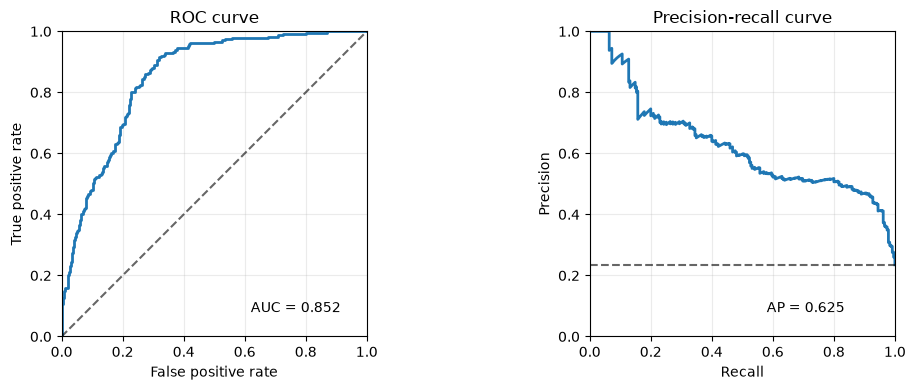

In [6]:
label_task = test_df.copy()
label_truth = test_df["label"].copy()
label_task["label"] = np.nan

label_pred = mimic.impute(label_task, columns=["label"])
y_true = label_truth.astype(str)
y_pred = label_pred["label"].astype(str)
label_confidence = mimic.confidence(label_task, columns=["label"])

label_diagnostics = binary_classification_diagnostics(
    y_true,
    y_pred,
    label_confidence,
    positive_label="minority",
    negative_label="majority",
)
label_examples = pd.DataFrame(
    {"true_label": y_true.head(12).to_numpy(), "predicted_label": y_pred.head(12).to_numpy()}
)

display(label_diagnostics.metrics.style.format({"value": "{:.3f}"}))
display(label_examples)
display(
    label_confidence[["prediction", "confidence", "entropy", "probability_margin", "vote_fraction"]]
    .head(12)
    .style.format(
        {
            "confidence": "{:.3f}",
            "entropy": "{:.3f}",
            "probability_margin": "{:.3f}",
            "vote_fraction": "{:.3f}",
        }
    )
)

fig, axes = plot_binary_classification_curves(label_diagnostics)

display(label_diagnostics.confusion_counts.style.set_caption("Confusion table: absolute counts"))
display(
    label_diagnostics.confusion_relative.style
    .format("{:.1%}")
    .set_caption("Confusion table: relative counts")
)


## 4. Synthetic generation

Generate synthetic rows, inspect traceability, and compare original and generated distributions in a shared 2D projection.

In [7]:
synthetic, trace = mimic.sample(len(test_df), return_trace=True)

display(test_df.head(12).style.set_caption("Held-out test rows"))
display(synthetic.head(12).style.set_caption("Displacement-generated rows"))
display(trace.head(12).style.set_caption("Generation trace"))


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,label
0,20,Private,177287,HS-grad,9,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,30,United-States,majority
1,25,Private,109419,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Female,0,0,40,United-States,majority
2,48,Private,238726,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,majority
3,37,Self-emp-not-inc,184655,HS-grad,9,Never-married,Craft-repair,Not-in-family,White,Male,0,0,35,United-States,majority
4,19,Private,87497,11th,7,Never-married,Transport-moving,Other-relative,White,Male,0,0,10,United-States,majority
5,35,Private,186110,HS-grad,9,Divorced,Transport-moving,Not-in-family,White,Male,0,0,45,United-States,majority
6,66,Self-emp-inc,112376,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,minority
7,22,Private,232985,HS-grad,9,Never-married,Handlers-cleaners,Other-relative,White,Male,0,0,20,United-States,majority
8,49,Private,123681,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,43,United-States,minority
9,56,Private,243076,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,0,40,United-States,majority


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,label
0,40,Private,197398,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,Black,Male,201,2177,48,United-States,minority
1,42,Self-emp-not-inc,131739,Assoc-voc,11,Married-civ-spouse,Exec-managerial,Husband,White,Male,4355,8,40,United-States,majority
2,37,Private,-25563,Bachelors,13,Never-married,Protective-serv,Not-in-family,White,Female,11,9,58,United-States,majority
3,39,Private,321716,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,41,0,40,United-States,majority
4,56,Private,267268,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,106,-1,67,United-States,minority
5,23,Private,314779,Some-college,10,Never-married,Handlers-cleaners,Not-in-family,White,Male,69,-11,40,United-States,majority
6,37,Private,91485,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,24,2,42,United-States,majority
7,44,State-gov,130766,Assoc-voc,10,Married-civ-spouse,Protective-serv,Husband,White,Male,42,-3,40,United-States,majority
8,21,Private,175702,Some-college,10,Never-married,Handlers-cleaners,Own-child,White,Male,-50,4,40,United-States,majority
9,35,State-gov,87967,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,-55,-1,33,United-States,majority


,trace_type,sample_index,lambda,neighbour_mode,condition,decoder,generation_decode_mode,resolved_generation_decode_mode,random_state,privacy_filter_enabled,privacy_filter_accepted,generation_attempt,method,anchor_index,displacement_from_index,displacement_to_index,restriction,sweep,column,task,sampled_value,conditioning,embedding_slice_start,embedding_slice_stop,member_index,component_index,component_probability,component_mean,component_sigma,sample_log_probability,sampled_class_code,class_probabilities
0,embedding,0,0.469439,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,0.000000,displacement,89.000000,512.000000,356.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
1,embedding,1,0.297089,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,1.000000,displacement,858.000000,327.000000,487.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
2,embedding,2,0.630570,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,2.000000,displacement,526.000000,990.000000,526.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
3,embedding,3,0.475193,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,3.000000,displacement,786.000000,56.000000,343.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
4,embedding,4,0.713382,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,4.000000,displacement,500.000000,50.000000,377.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
5,embedding,5,0.661381,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,5.000000,displacement,781.000000,670.000000,178.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
6,embedding,6,0.363619,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,6.000000,displacement,545.000000,101.000000,545.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
7,embedding,7,0.663816,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,7.000000,displacement,554.000000,327.000000,858.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
8,embedding,8,0.629044,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,8.000000,displacement,276.000000,178.000000,276.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
9,embedding,9,0.735349,mutual,None,NeuralConditionalSampler,auto,factorised,42.000000,False,True,9.000000,displacement,354.000000,74.000000,470.000000,basic,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: divide by zero encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: overflow encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: invalid value encountered in matmul
  B = -0.5 * J @ D2 @ J


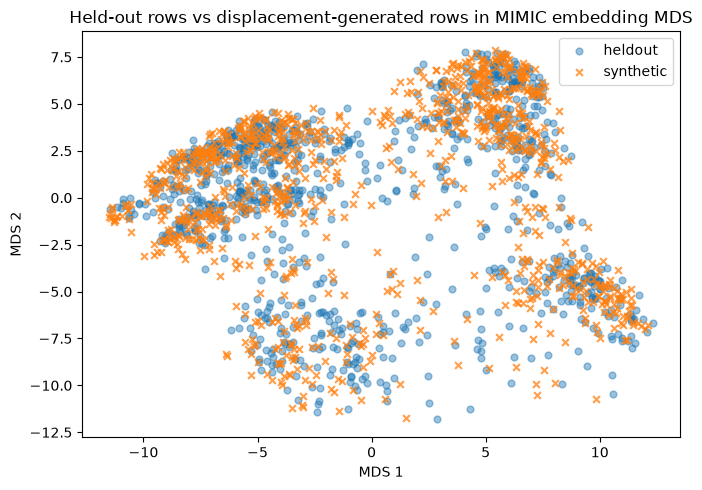

In [8]:
combined = pd.concat(
    [test_df.assign(source="heldout"), synthetic.assign(source="synthetic")],
    ignore_index=True,
)

# Use MIMIC's fitted embedding for both original and generated rows, then project jointly with classical MDS.
H_combined = mimic.transform(combined.drop(columns=["source"]))
plot_df = classical_mds_2d(H_combined, random_state=RANDOM_STATE)
plot_df["source"] = combined["source"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 5))
for source, marker, alpha in [("heldout", "o", 0.45), ("synthetic", "x", 0.75)]:
    part = plot_df[plot_df["source"] == source]
    ax.scatter(part["mds1"], part["mds2"], label=source, marker=marker, alpha=alpha, s=24)
ax.set_title("Held-out rows vs displacement-generated rows in MIMIC embedding MDS")
ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.legend()
fig.tight_layout()

In [9]:
summary = pd.concat(
    [test_df[regression_columns].describe().T.add_prefix("heldout_"), synthetic[regression_columns].describe().T.add_prefix("synthetic_")],
    axis=1,
)
comparison_summary = summary[["heldout_mean", "synthetic_mean", "heldout_std", "synthetic_std"]]
display(comparison_summary.style.format("{:.2f}"))

,heldout_mean,synthetic_mean,heldout_std,synthetic_std
age,38.11,37.79,13.43,13.87
fnlwgt,193070.77,184217.77,108297.50,103565.80
education-num,10.14,10.02,2.66,2.42
capital-gain,1095.66,922.74,7966.43,6712.11
capital-loss,66.22,117.34,346.84,442.04
hours-per-week,39.95,40.39,12.10,12.95


Text(0.5, 1.02, 'Pairwise numeric feature statistics: held-out vs displacement-generated')

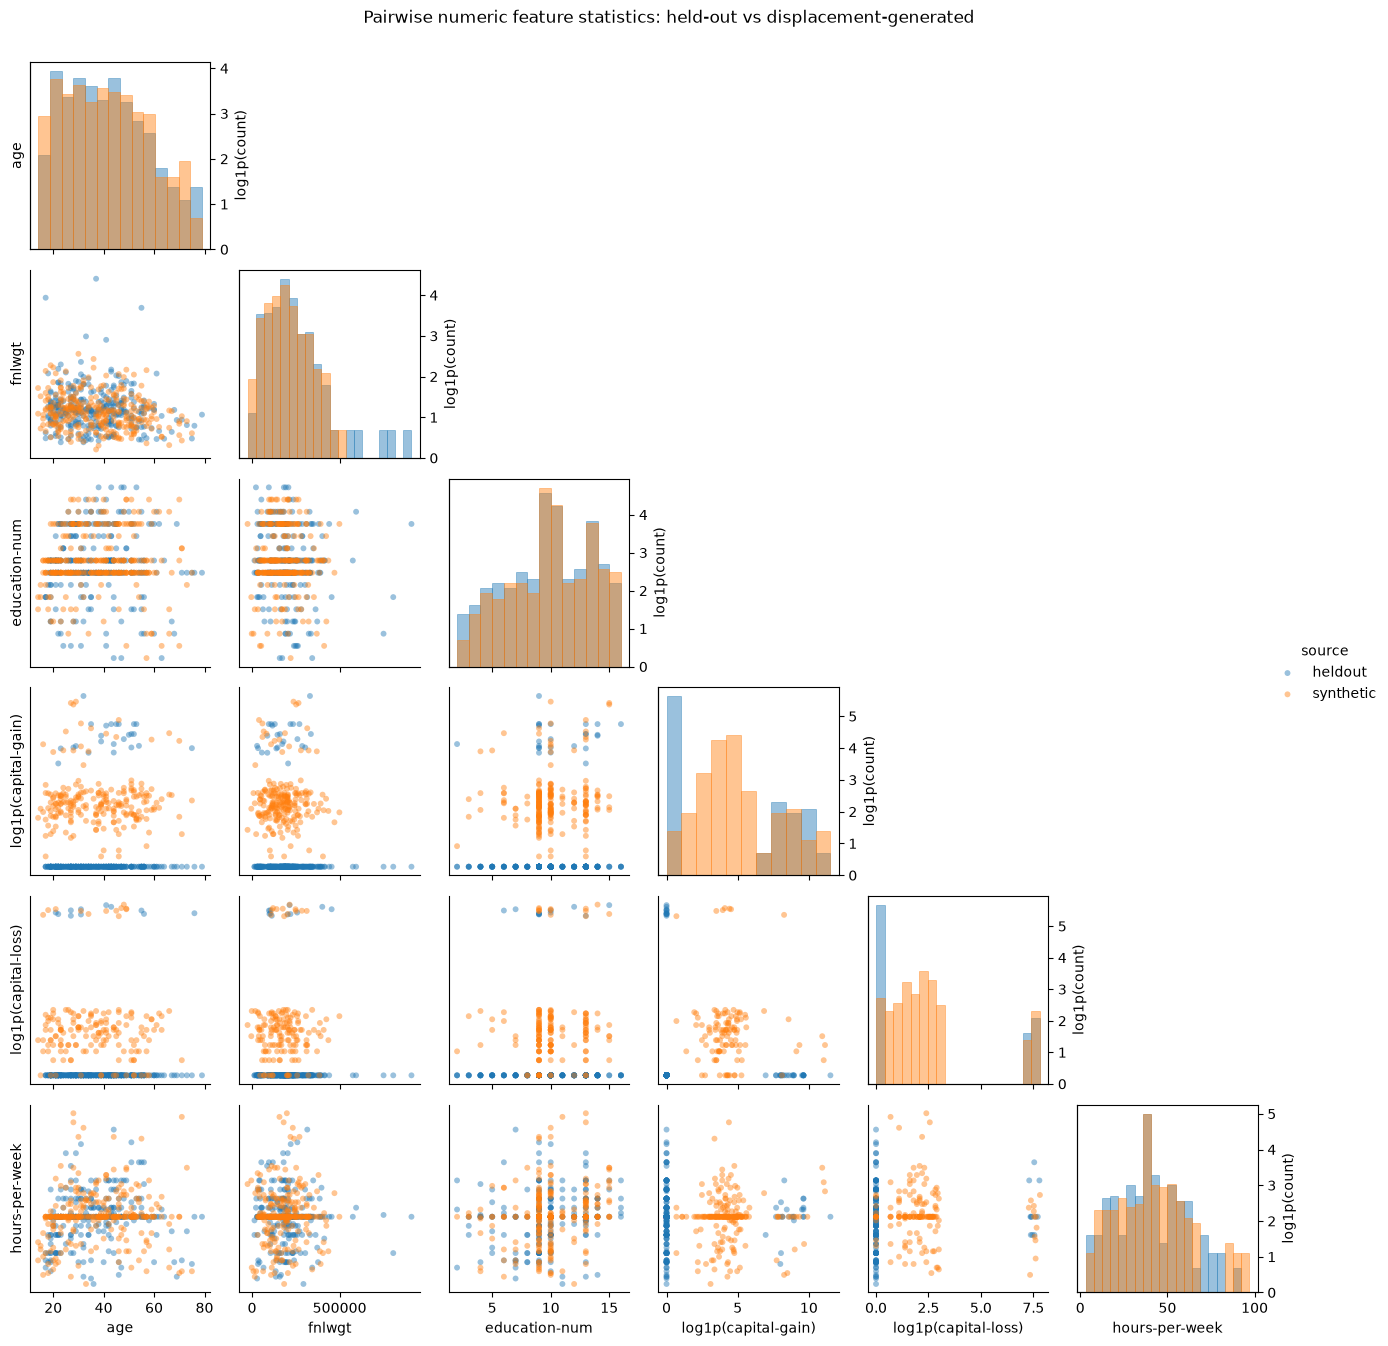

In [10]:
pair_grid = pairwise_feature_plot(
    test_df,
    synthetic,
    features=regression_columns,
    log1p_features=[c for c in ["capital-gain", "capital-loss", "balance", "LIMIT_BAL"] if c in regression_columns],
    original_label="heldout",
    generated_label="synthetic",
    max_rows_per_source=300,
    random_state=RANDOM_STATE,
)
pair_grid.fig.suptitle("Pairwise numeric feature statistics: held-out vs displacement-generated", y=1.02)


### Categorical feature distributions


,feature,total_variation_distance,n_categories
3,occupation,0.146,14
4,relationship,0.077,6
1,education,0.074,16
7,native-country,0.059,37
6,sex,0.056,2
0,workclass,0.055,7
2,marital-status,0.052,6
5,race,0.025,5
8,label,0.006,2


,feature,category,heldout_proportion,synthetic_proportion,absolute_difference
6,education,HS-grad,32.5%,37.7%,5.2%
7,education,Bachelors,17.5%,14.3%,3.2%
8,education,11th,3.1%,4.3%,1.2%
9,education,Doctorate,1.8%,0.8%,1.0%
10,education,Some-college,20.6%,21.5%,0.9%
11,education,9th,2.0%,1.2%,0.8%
43,label,majority,76.5%,75.9%,0.6%
44,label,minority,23.5%,24.1%,0.6%
12,marital-status,Married-civ-spouse,43.5%,48.7%,5.2%
13,marital-status,Never-married,34.1%,32.0%,2.1%


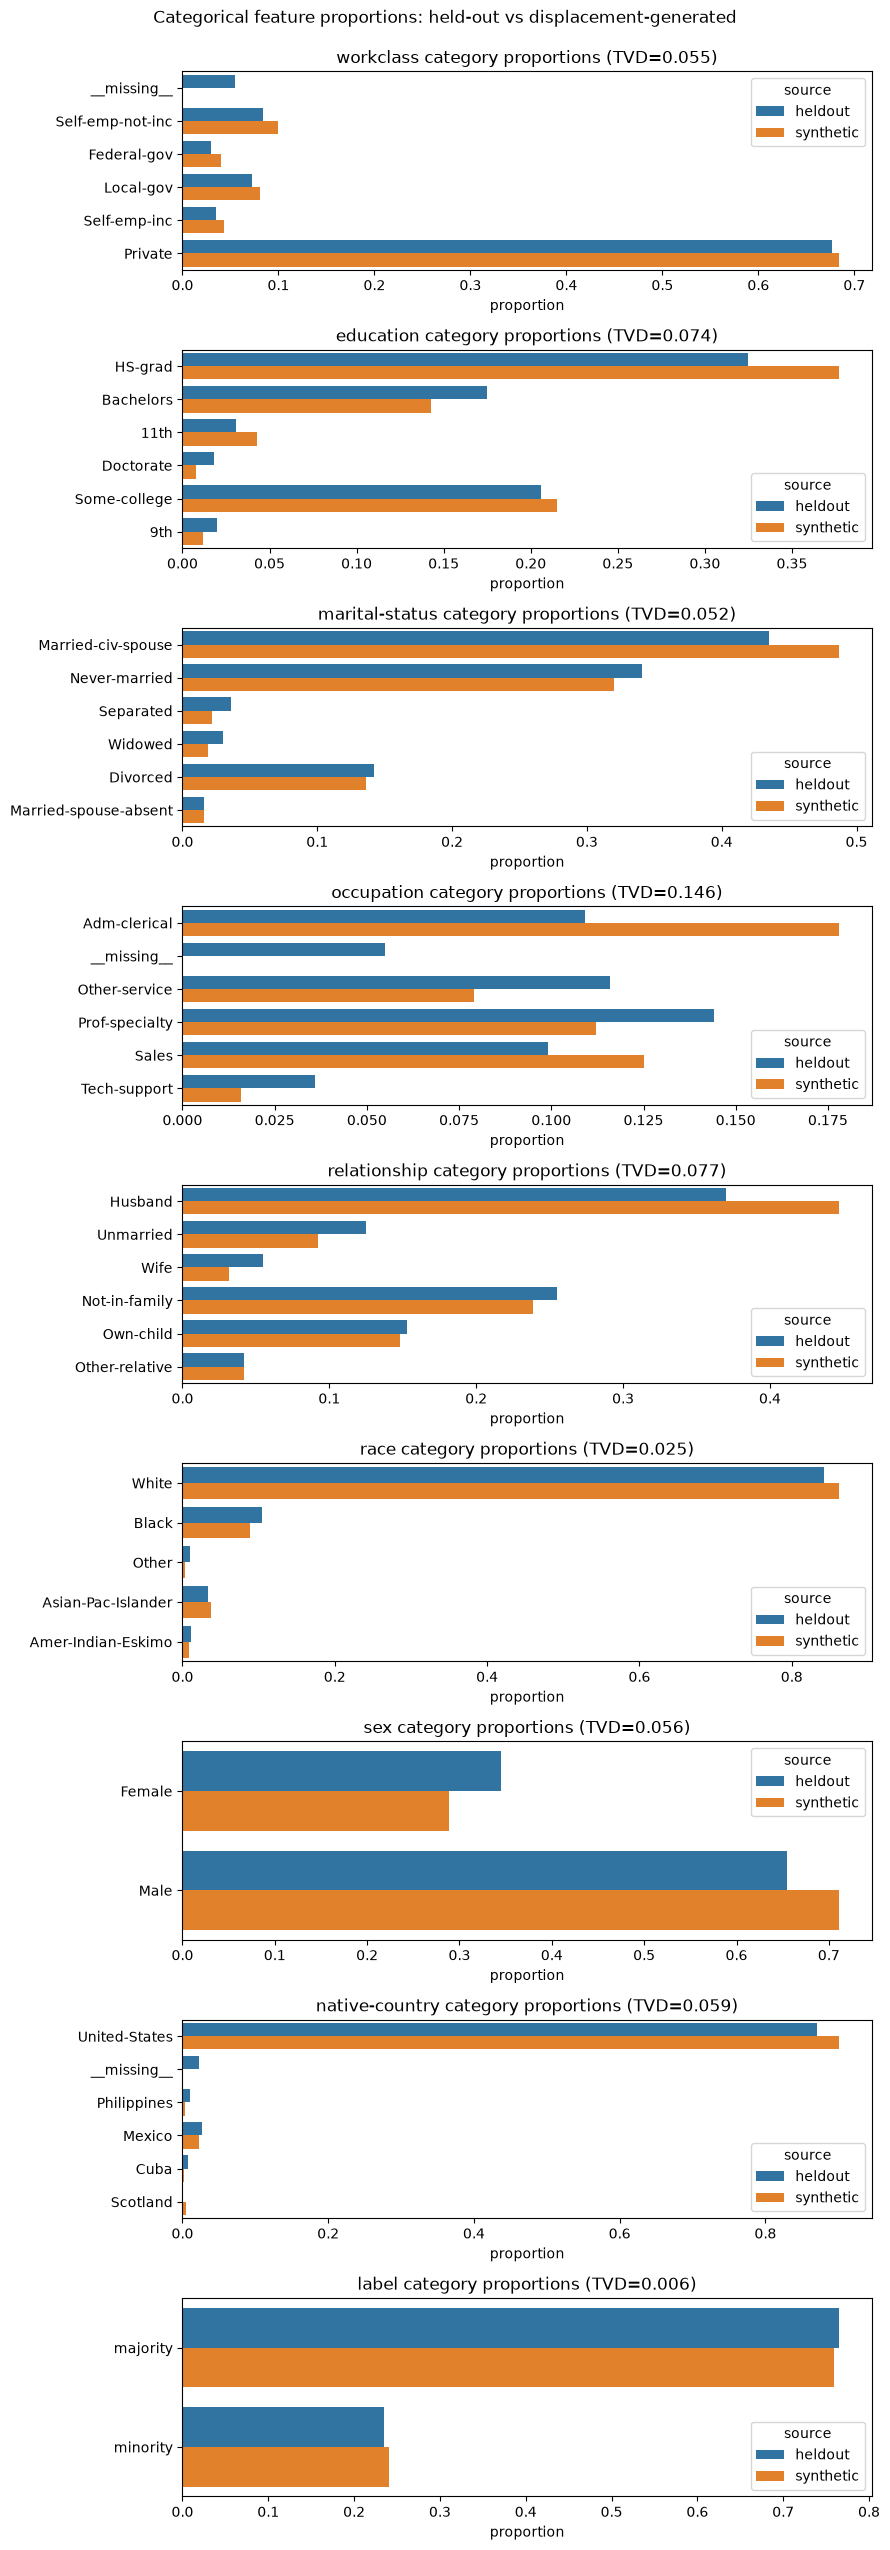

In [11]:
categorical_fig, categorical_axes, categorical_report, categorical_summary = categorical_feature_plot(
    test_df,
    synthetic,
    features=classification_columns,
    original_label="heldout",
    generated_label="synthetic",
    top_n=6,
)
categorical_fig.suptitle("Categorical feature proportions: held-out vs displacement-generated", y=1.01)
display(
    categorical_summary.sort_values("total_variation_distance", ascending=False)
    .style.format({"total_variation_distance": "{:.3f}"})
)
display(
    categorical_report.sort_values(["feature", "absolute_difference"], ascending=[True, False])
    .style.format(
        {
            "heldout_proportion": "{:.1%}",
            "synthetic_proportion": "{:.1%}",
            "absolute_difference": "{:.1%}",
        }
    )
)


## 5. Feature-wise embedding projections

Each panel projects one feature-specific embedding block to 2D and colours rows by that same raw feature value.


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: divide by zero encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: overflow encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: invalid value encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/.venvs/py312/lib/python3.12/site-packag

Text(0.5, 1.01, 'Feature-wise MIMIC embeddings coloured by their own values')

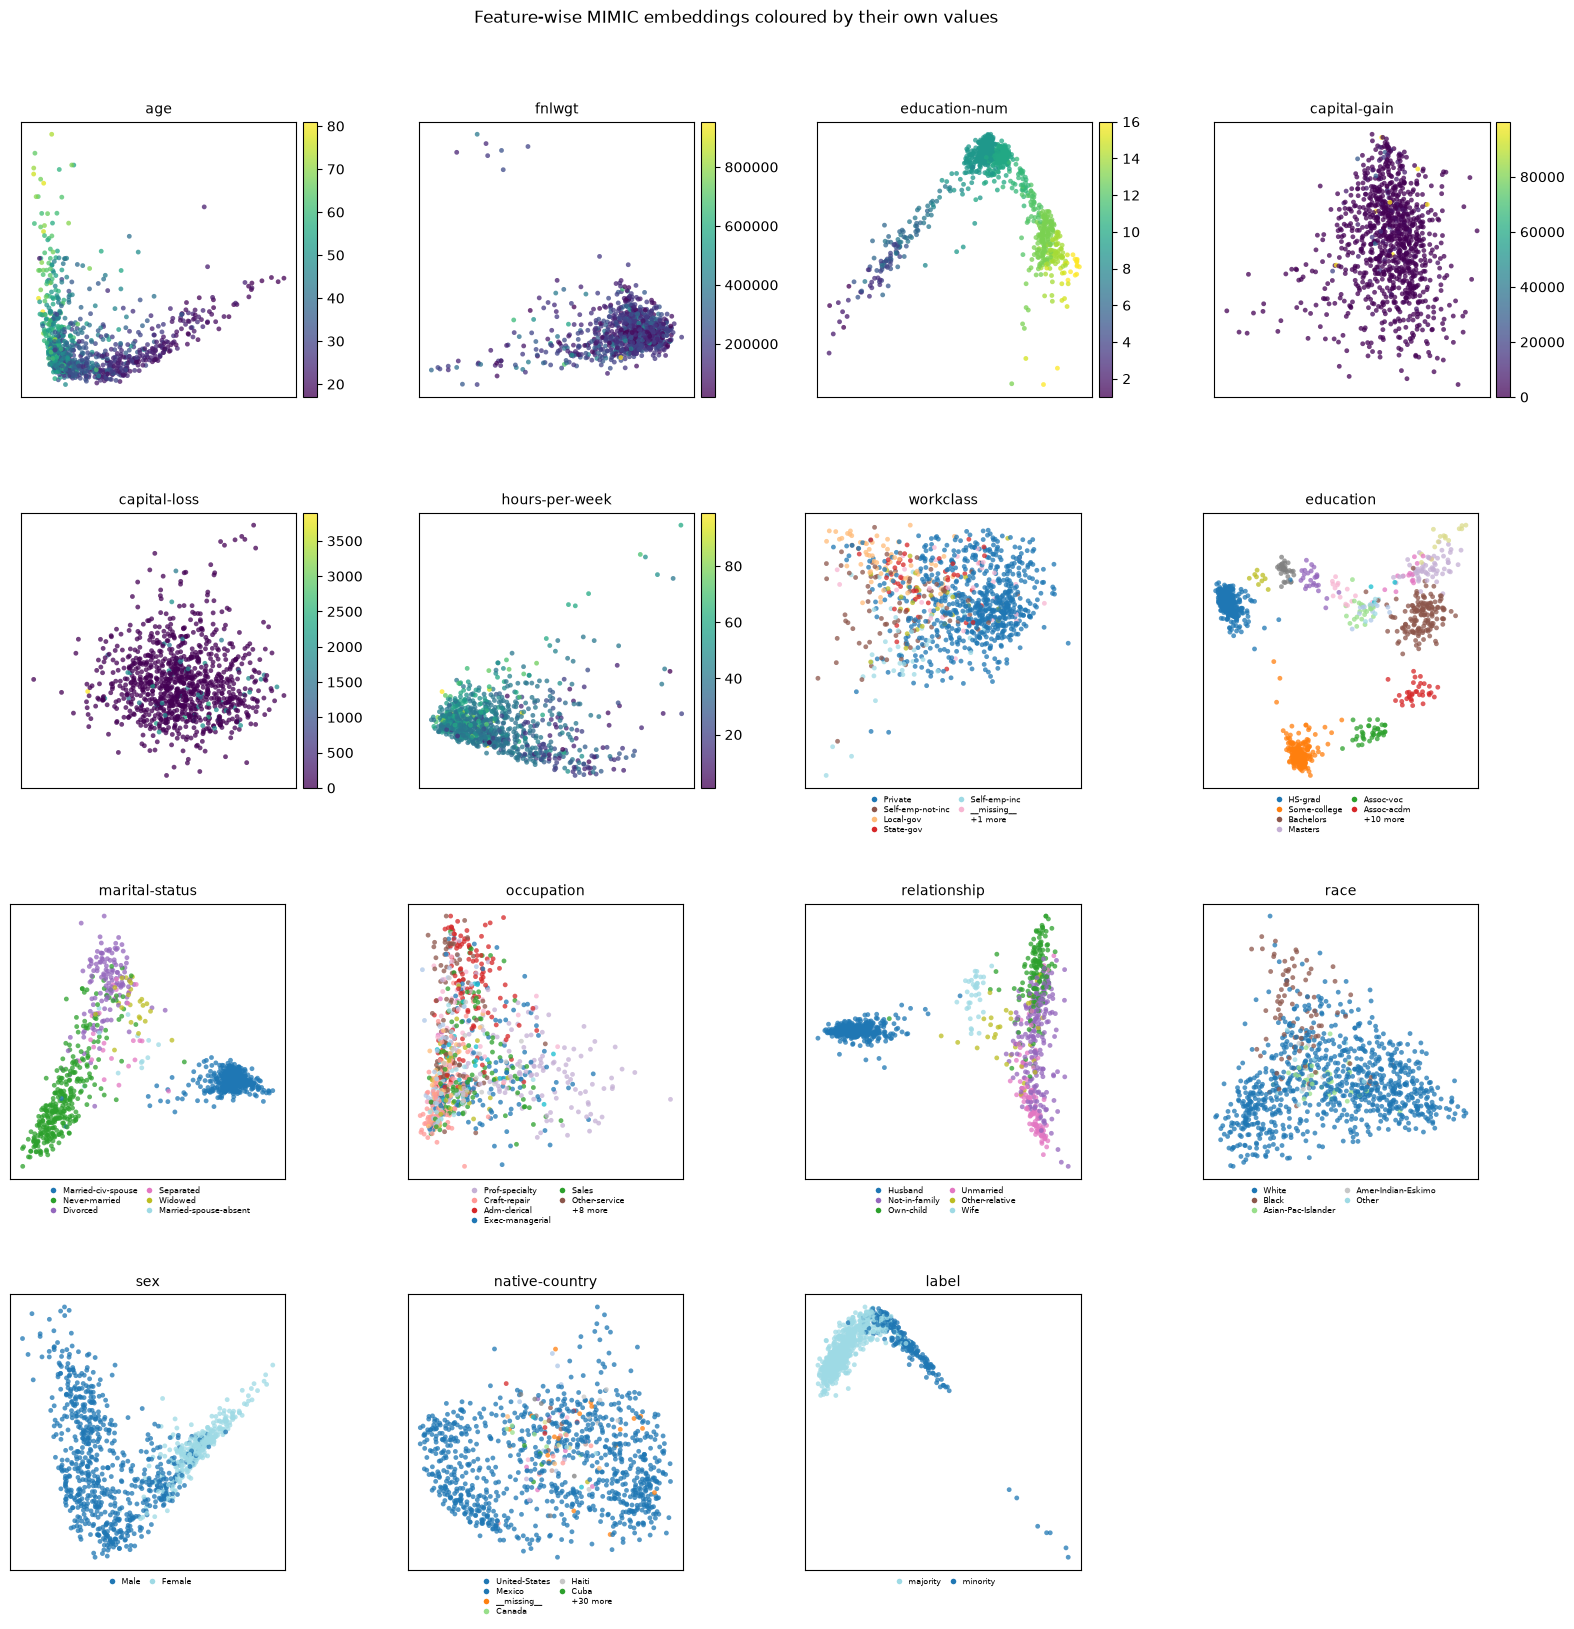

In [12]:
feature_grid_fig, feature_grid_axes = plot_feature_embedding_grid(
    mimic,
    df,
    columns=model_columns,
    n_cols=4,
    size=(4,4),
    random_state=RANDOM_STATE,
)
feature_grid_fig.suptitle("Feature-wise MIMIC embeddings coloured by their own values", y=1.01)


### Full embedding colored by each feature


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: divide by zero encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: overflow encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: invalid value encountered in matmul
  B = -0.5 * J @ D2 @ J


Text(0.5, 1.01, 'Full MIMIC embedding coloured by each feature')

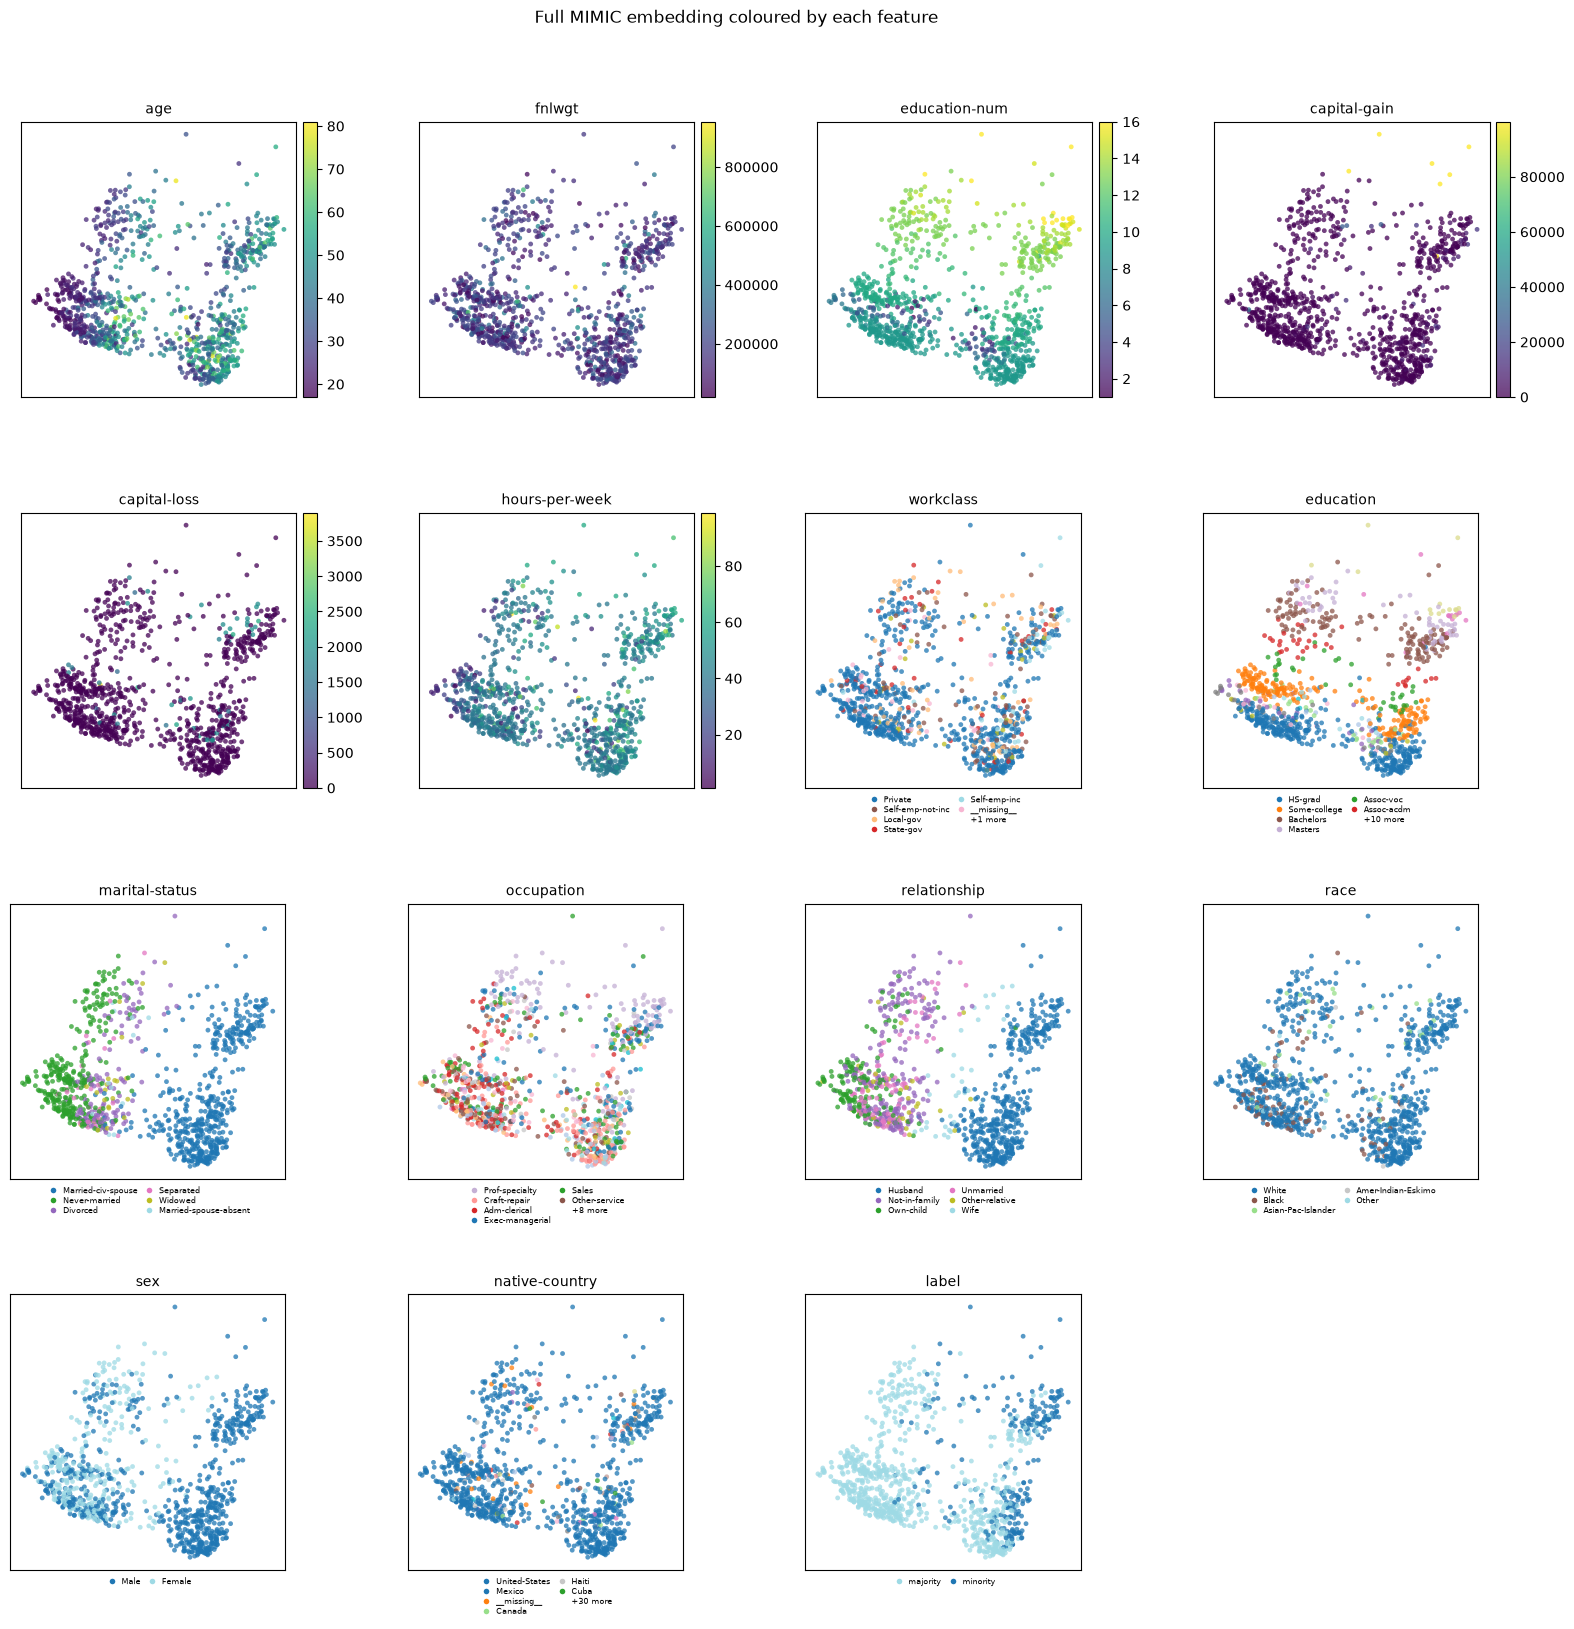

In [13]:
global_grid_fig, global_grid_axes = plot_global_embedding_color_grid(
    mimic,
    df,
    columns=model_columns,
    n_cols=4,
    size=(4, 4),
    random_state=RANDOM_STATE,
)
global_grid_fig.suptitle("Full MIMIC embedding coloured by each feature", y=1.01)


## 6. Pareto feature-pair views

Feature pairs are selected on two objectives: high average association with `label` and low association between the two features. Each Pareto-front pair is plotted in 2D and coloured by `label`.


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: divide by zero encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: overflow encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/Documents/Projects/Repositories/ACTIVE/MIMIC/src/mimic/diagnostics.py:50: RuntimeWarning: invalid value encountered in matmul
  B = -0.5 * J @ D2 @ J
/Users/f.costa/.venvs/py312/lib/python3.12/site-packag

,feature_x,feature_y,target_association,pair_association,pareto
0,marital-status,relationship,0.487,0.495,True
1,education,relationship,0.431,0.161,True
2,capital-gain,relationship,0.352,0.087,True
3,capital-gain,marital-status,0.344,0.082,True
4,capital-loss,relationship,0.306,0.078,True
5,capital-loss,marital-status,0.298,0.074,True


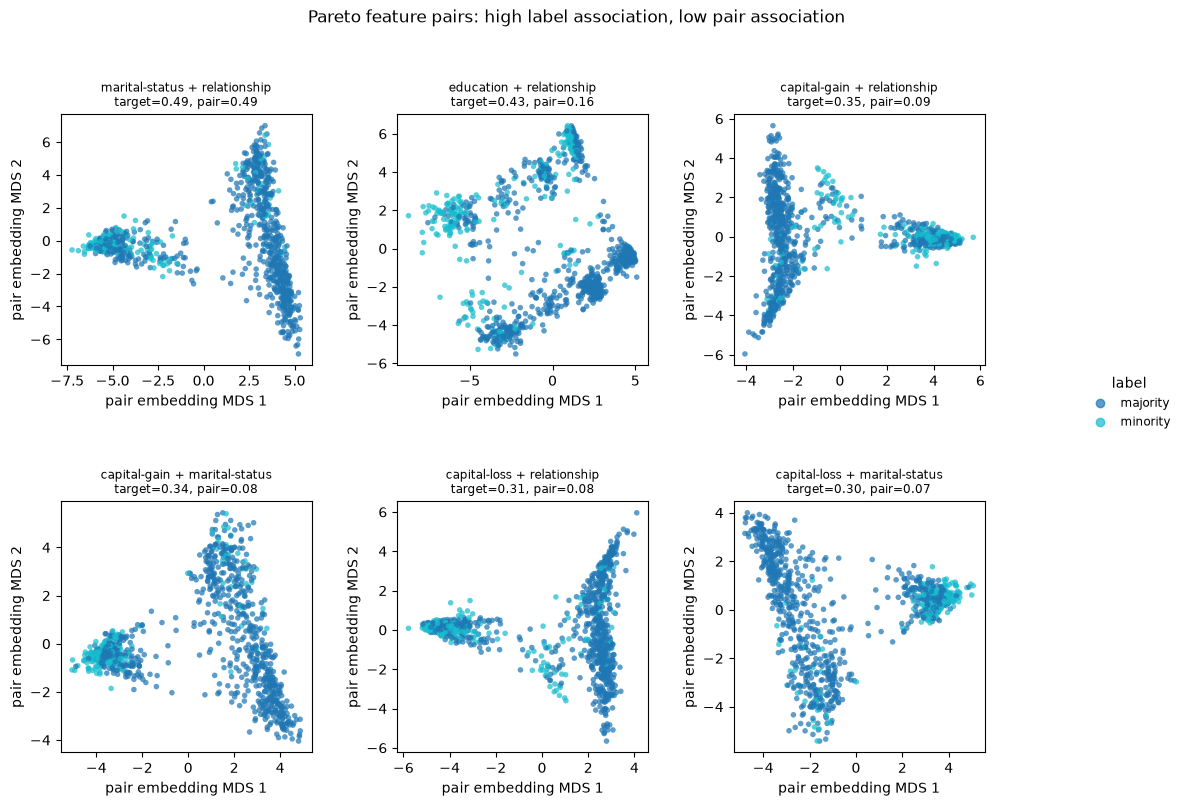

In [14]:
pareto_fig, pareto_axes, pareto_pairs = plot_pareto_feature_pairs(
    mimic,
    test_df,
    target="label",
    columns=[c for c in model_columns if c != "label"],
    max_pairs=6,
    size=(4,4),
)
pareto_fig.suptitle("Pareto feature pairs: high label association, low pair association", y=1.02)
display(
    pareto_pairs[pareto_pairs["pareto"]]
    .head(12)
    .style.format({"target_association": "{:.3f}", "pair_association": "{:.3f}"})
)
